# Impact Financing anouncements on the stock prices

In [29]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, avg, stddev
import matplotlib.pyplot as plt
import pandas as pd

In [30]:
# Initialize Spark Session with appropriate configurations for local execution
spark = (SparkSession.builder
    .master("local[*]")  # Run Spark locally with as many worker threads as logical cores
    .appName("FinancialAnnouncementsImpact")  # Name the Spark application
    .config("spark.driver.memory", "2g")  # Allocate 2 GB of memory to the Spark driver
    .config("spark.executor.memory", "2g")  # Allocate 2 GB of memory to each Spark executor
    .config("spark.ui.enabled", "true")  # Enable Spark UI
    .config("spark.ui.port", "0")  # Let Spark pick a free UI port
    .getOrCreate())

sc = spark.sparkContext  # Access SparkContext if needed

In [89]:
# Load the daily_data_parquet and biweekly_basetable_w_sentiment_5.parquet files into Spark DataFrames
daily_data_df = spark.read.parquet("../Cleaned_data/daily_data.parquet")
biweekly_data_df = spark.read.parquet("../Cleaned_data/biweekly_basetable_w_sentiment_5.parquet")

# Display the schema of the daily_data_parquet DataFrame
print("Schema of daily_data_parquet:")
daily_data_df.printSchema()

# Display the schema of the biweekly_basetable_w_sentiment_5.parquet DataFrame
print("\nSchema of biweekly_basetable_w_sentiment_5.parquet:")
biweekly_data_df.printSchema()

# Count the number of rows in each DataFrame
daily_data_count = daily_data_df.count()
biweekly_data_count = biweekly_data_df.count()

print(f"\nNumber of rows in daily_data_parquet: {daily_data_count}")
print(f"Number of rows in biweekly_basetable_w_sentiment_5.parquet: {biweekly_data_count}")

# Show the first few rows of each DataFrame for basic exploration
print("\nSample rows from daily_data_parquet:")
daily_data_df.show(5)

print("\nSample rows from biweekly_basetable_w_sentiment_5.parquet:")
biweekly_data_df.show(5)

Schema of daily_data_parquet:
root
 |-- ticker: string (nullable = true)
 |-- Local Date (ET): date (nullable = true)
 |-- Open: double (nullable = true)
 |-- High: double (nullable = true)
 |-- Low: double (nullable = true)
 |-- Close: double (nullable = true)
 |-- Volume: double (nullable = true)
 |-- daily_return: double (nullable = true)
 |-- %Chg: double (nullable = true)
 |-- intraday_return: double (nullable = true)
 |-- intraday_range: double (nullable = true)
 |-- gap: double (nullable = true)
 |-- up_day: integer (nullable = true)
 |-- down_day: integer (nullable = true)
 |-- volume_up: double (nullable = true)
 |-- volume_down: double (nullable = true)
 |-- days_since_start: integer (nullable = true)
 |-- biweekly_index: integer (nullable = true)
 |-- biweekly_period: string (nullable = true)
 |-- longName: string (nullable = true)
 |-- industry: string (nullable = true)


Schema of biweekly_basetable_w_sentiment_5.parquet:
root
 |-- industry: string (nullable = true)
 |-- b

In [90]:
daily_data_df.show(5)
biweekly_data_df.show(5)

+------+---------------+----+----+----+-----+--------+--------------------+-------------------+--------------------+--------------------+--------------------+------+--------+---------+-----------+----------------+--------------+---------------+--------------------+--------+
|ticker|Local Date (ET)|Open|High| Low|Close|  Volume|        daily_return|               %Chg|     intraday_return|      intraday_range|                 gap|up_day|down_day|volume_up|volume_down|days_since_start|biweekly_index|biweekly_period|            longName|industry|
+------+---------------+----+----+----+-----+--------+--------------------+-------------------+--------------------+--------------------+--------------------+------+--------+---------+-----------+----------------+--------------+---------------+--------------------+--------+
|ARG.TO|     2024-01-15|1.36|1.38|1.35| 1.38| 71200.0|                NULL|               NULL|0.014705882352941025| 0.02205882352941162|                NULL|     1|       0| 

In [91]:
# Alias the DataFrames to avoid ambiguity in column names
daily_data_df_alias = daily_data_df.alias("daily")
biweekly_data_df_alias = biweekly_data_df.alias("biweekly")

# Perform a join operation between daily_data_df and biweekly_data_df on the "biweekly_index" column
# This will combine the daily stock data with the biweekly sentiment data for analysis
joined_df = daily_data_df_alias.join(biweekly_data_df_alias, on="biweekly_index", how="inner")

# Select relevant columns for analysis, explicitly specifying the DataFrame aliases
joined_df = joined_df.select(
	col("daily.ticker").alias("ticker"),
    col("daily.industry").alias("industry"),
	col("daily.Local Date (ET)").alias("Local Date (ET)"),
	col("daily.Close").alias("Close"),
	col("daily.daily_return").alias("daily_return"),
    col("biweekly.has_financing").alias("has_financing"),
)

# Display the schema and a sample of the joined DataFrame
print("\nSchema of the joined DataFrame:")
joined_df.printSchema()

print("\nSample rows from the joined DataFrame:")
joined_df.show(5)


Schema of the joined DataFrame:
root
 |-- ticker: string (nullable = true)
 |-- industry: string (nullable = true)
 |-- Local Date (ET): date (nullable = true)
 |-- Close: double (nullable = true)
 |-- daily_return: double (nullable = true)
 |-- has_financing: integer (nullable = true)


Sample rows from the joined DataFrame:
+------+--------+---------------+-----+--------------------+-------------+
|ticker|industry|Local Date (ET)|Close|        daily_return|has_financing|
+------+--------+---------------+-----+--------------------+-------------+
|ARG.TO|  Copper|     2024-01-15| 1.38|                NULL|            0|
|ARG.TO|  Copper|     2024-01-15| 1.38|                NULL|            0|
|ARG.TO|  Copper|     2024-01-15| 1.38|                NULL|            0|
|ARG.TO|  Copper|     2024-01-15| 1.38|                NULL|            0|
|ARG.TO|  Copper|     2024-01-16| 1.35|-0.02173913043478...|            0|
+------+--------+---------------+-----+--------------------+-----------

In [92]:
from pyspark.sql.window import Window
from pyspark.sql.functions import lag, lead, col, avg

# Calculate stock price changes before and after financial announcements for each company

# Define a window specification to calculate stock prices before and after announcements
window_spec = Window.partitionBy("ticker").orderBy("Local Date (ET)")

# Calculate the stock price one day before and one day after the announcement
joined_df = joined_df.withColumn("price_before", lag("Close", 1).over(window_spec))
joined_df = joined_df.withColumn("price_after", lead("Close", 1).over(window_spec))

# Calculate the percentage change in stock price
joined_df = joined_df.withColumn(
    "price_change",
    ((col("price_after") - col("price_before")) / col("price_before")) * 100
)

# Filter rows where price_before or price_after is null (e.g., first or last row in the window)
joined_df = joined_df.filter(col("price_before").isNotNull() & col("price_after").isNotNull())

# Group by ticker and calculate the average price change
impact_analysis_df = joined_df.groupBy("ticker").agg(
    avg("price_change").alias("avg_price_change")
)

# Display the results
print("\nImpact analysis results:")
impact_analysis_df.show(10)


Impact analysis results:
+------+--------------------+
|ticker|    avg_price_change|
+------+--------------------+
|ARG.TO| 0.02249117664055592|
|AYA.TO| 0.00463574315371661|
| CG.TO|0.028914475689685273|
| CGC.V| 0.05934072265994058|
| CKG.V|  0.0497469307707029|
| DMX.V| 0.08285907330976024|
|  DV.V|0.018321550400907258|
| EDG.V| 0.04671001466577551|
|ELO.TO|-0.00115265589427...|
|   EQX| 0.02603215535897055|
+------+--------------------+
only showing top 10 rows


In [93]:
from pyspark.sql.functions import avg

# Calculate the average sentiment score for each company from biweekly_data_df
avg_sentiment_df = biweekly_data_df.groupBy("ticker").agg(
    avg("avg_vader_ca").alias("avg_sentiment_score")
)

# Join the average sentiment scores with the impact analysis DataFrame
impact_analysis_with_sentiment_df = impact_analysis_df.join(
    avg_sentiment_df, on="ticker", how="inner"
)

# Convert the resulting DataFrame to a Pandas DataFrame for visualization
impact_analysis_pd = impact_analysis_with_sentiment_df.toPandas()

# Display the first few rows of the resulting DataFrame
print(impact_analysis_pd.head())

   ticker  avg_price_change  avg_sentiment_score
0  ARG.TO          0.022491             0.221235
1  AYA.TO          0.004636             0.188256
2   CG.TO          0.028914             0.148308
3   CGC.V          0.059341             0.195607
4   CKG.V          0.049747             0.121573


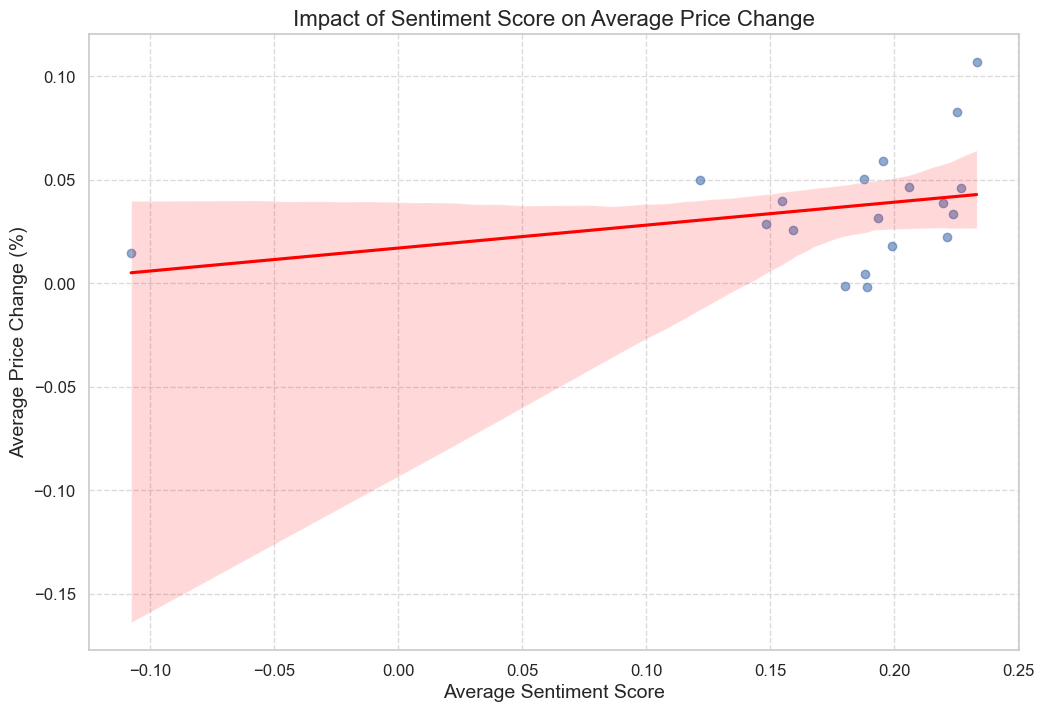

In [94]:
import seaborn as sns

import matplotlib.pyplot as plt

# Set the style for the plots
sns.set(style="whitegrid")

# Create a scatter plot with regression line to visualize the relationship
plt.figure(figsize=(12, 8))
sns.regplot(
    x="avg_sentiment_score",
    y="avg_price_change",
    data=impact_analysis_pd,
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)
plt.title("Impact of Sentiment Score on Average Price Change", fontsize=16)
plt.xlabel("Average Sentiment Score", fontsize=14)
plt.ylabel("Average Price Change (%)", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()

/var/folders/w0/4x15r9493sg93bbb6zq0__q80000gn/T/ipykernel_1608/3520605004.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


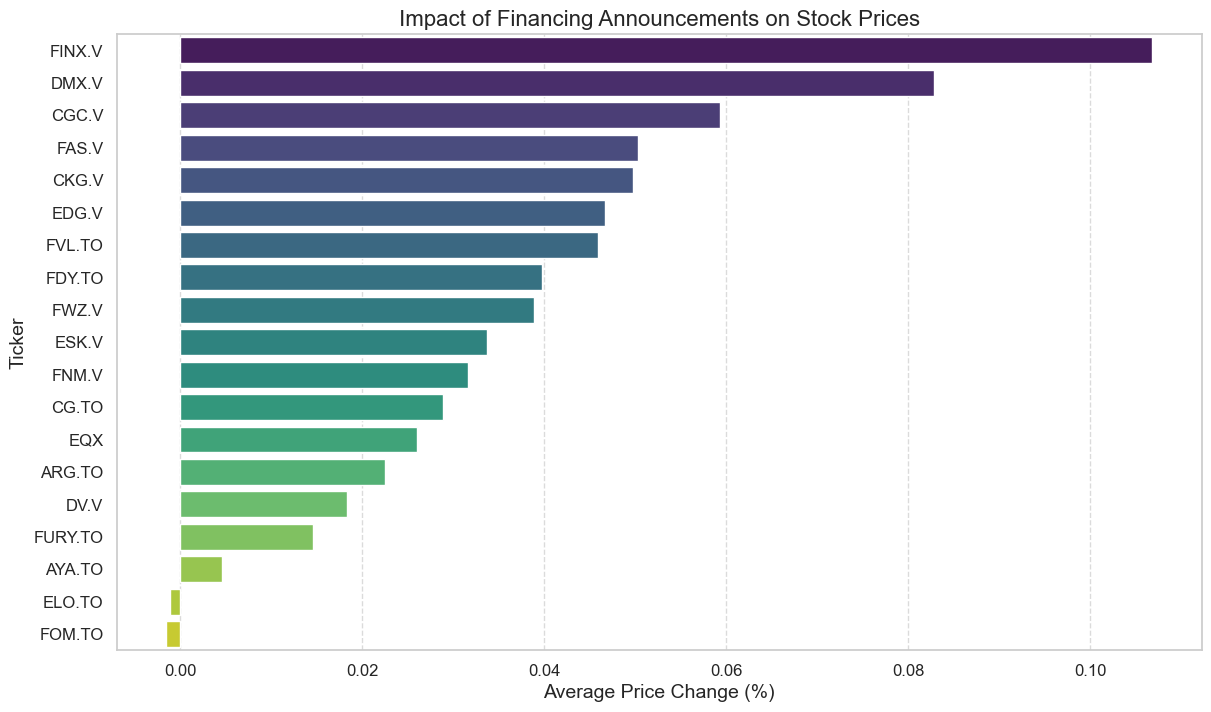

In [95]:
# Filter companies with financing announcements
financing_impact_df = impact_analysis_pd[impact_analysis_pd['avg_price_change'] != 0]

# Sort the data by average price change for better visualization
financing_impact_df = financing_impact_df.sort_values(by='avg_price_change', ascending=False)

# Plot the impact of financing announcements on stock prices
plt.figure(figsize=(14, 8))
sns.barplot(
    x='avg_price_change',
    y='ticker',
    data=financing_impact_df,
    palette='viridis'
)
plt.title("Impact of Financing Announcements on Stock Prices", fontsize=16)
plt.xlabel("Average Price Change (%)", fontsize=14)
plt.ylabel("Ticker", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

In [102]:
from pyspark.sql.functions import avg

# Calculate the average sentiment score for each company from biweekly_data_df
avg_sentiment_df = biweekly_data_df.groupBy("industry").agg(
    avg("avg_vader_ca").alias("avg_sentiment_score")
)

# Ensure the `industry` column is included in the impact_analysis_df DataFrame
impact_analysis_df_with_industry = joined_df.groupBy("industry", "industry").agg(
    avg("price_change").alias("avg_price_change")
)

# Join the average sentiment scores with the updated impact analysis DataFrame
impact_analysis_with_sentiment_df = impact_analysis_df_with_industry.join(
    avg_sentiment_df, on="industry", how="inner"
)

# Convert the resulting DataFrame to a Pandas DataFrame for visualization
impact_analysis_pd = impact_analysis_with_sentiment_df.toPandas()

# Display the first few rows of the resulting DataFrame
print(impact_analysis_pd.head())

                           industry  avg_price_change  avg_sentiment_score
0                            Copper          0.030306             0.196204
1                            Silver          0.011548             0.193789
2  Other Industrial Metals & Mining          0.037848             0.174044
3    Other Precious Metals & Mining          0.042826             0.169535
4                              Gold          0.034319             0.181372


/var/folders/w0/4x15r9493sg93bbb6zq0__q80000gn/T/ipykernel_1608/1139460241.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


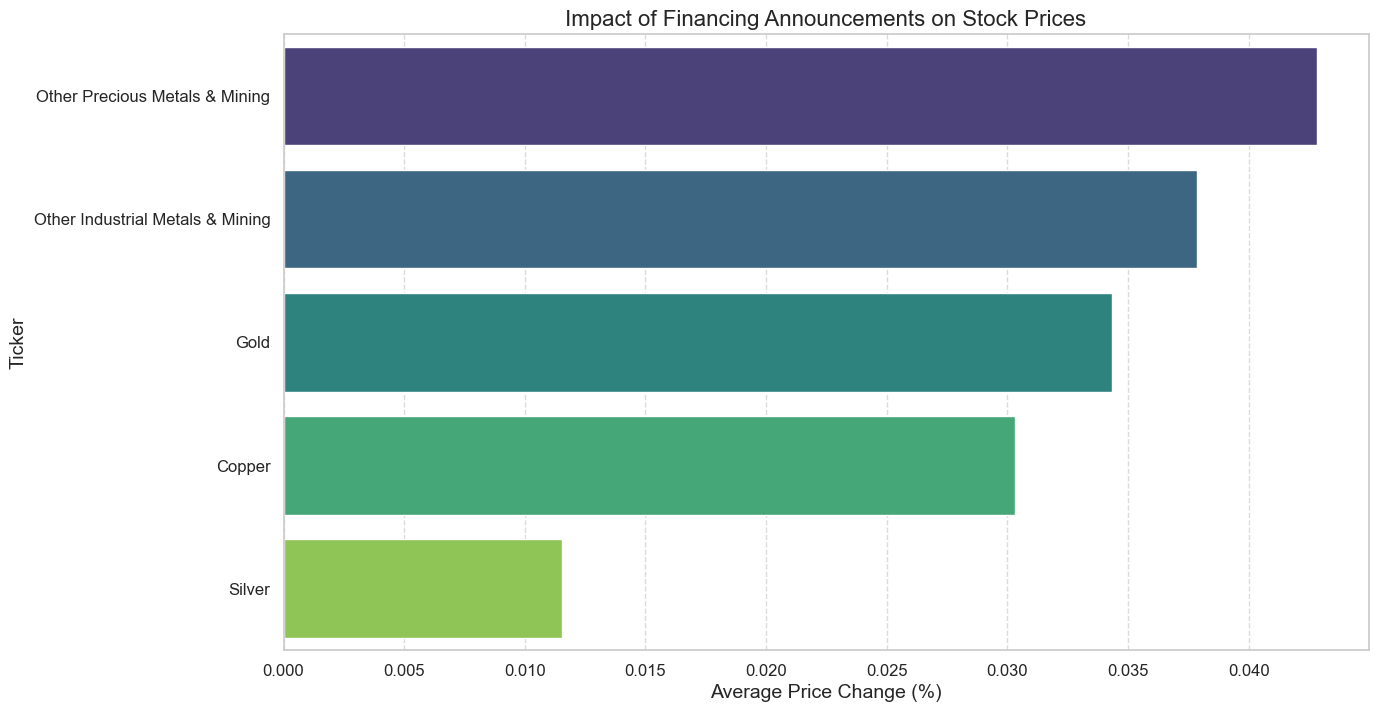

In [103]:
# Filter companies with financing announcements
financing_impact_df = impact_analysis_pd[impact_analysis_pd['avg_price_change'] != 0]

# Sort the data by average price change for better visualization
financing_impact_df = financing_impact_df.sort_values(by='avg_price_change', ascending=False)

# Plot the impact of financing announcements on stock prices
plt.figure(figsize=(14, 8))
sns.barplot(
    x='avg_price_change',
    y='industry',
    data=financing_impact_df,
    palette='viridis'
)
plt.title("Impact of Financing Announcements on Stock Prices", fontsize=16)
plt.xlabel("Average Price Change (%)", fontsize=14)
plt.ylabel("Ticker", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

In [11]:
from pyspark.sql.window import Window
from pyspark.sql.functions import col, avg, when

# Define a window specification partitioned by ticker and ordered by date
window_spec = Window.partitionBy("ticker").orderBy("Local Date (ET)")

# Calculate the percentage change for the specified days relative to financing announcements
for offset in range(-3, 4):  # -3 to +3 days
    joined_df = joined_df.withColumn(
        f"price_change_day_{offset}",
        ((col("Close") - lag("Close", -offset).over(window_spec)) / lag("Close", -offset).over(window_spec)) * 100
    )

# Filter rows where a financing announcement occurred
financing_days_df = joined_df.filter(col("current_financing_announcement") == 1)

# Calculate the average percentage change for each ticker
average_changes_df = financing_days_df.groupBy("ticker").agg(
    *[avg(f"price_change_day_{offset}").alias(f"avg_price_change_day_{offset}") for offset in range(-3, 4)]
)

# Display the results
print("\nAverage percentage changes for each ticker:")
average_changes_df.show()


Average percentage changes for each ticker:


+-------+-----------------------+-----------------------+-----------------------+----------------------+----------------------+----------------------+----------------------+
| ticker|avg_price_change_day_-3|avg_price_change_day_-2|avg_price_change_day_-1|avg_price_change_day_0|avg_price_change_day_1|avg_price_change_day_2|avg_price_change_day_3|
+-------+-----------------------+-----------------------+-----------------------+----------------------+----------------------+----------------------+----------------------+
| ARG.TO|   0.027465540314558612|   0.022828083290770174|                    0.0|                   0.0|                   0.0|  0.002988846210326707|  -0.03155320575471022|
| AYA.TO|    0.12163119151214798|                    0.0|                    0.0|                   0.0|                   0.0|                   0.0|   0.08409023232947571|
|  CG.TO|    0.04974830072178591|                    0.0|                    0.0|                   0.0|                   0.0|   

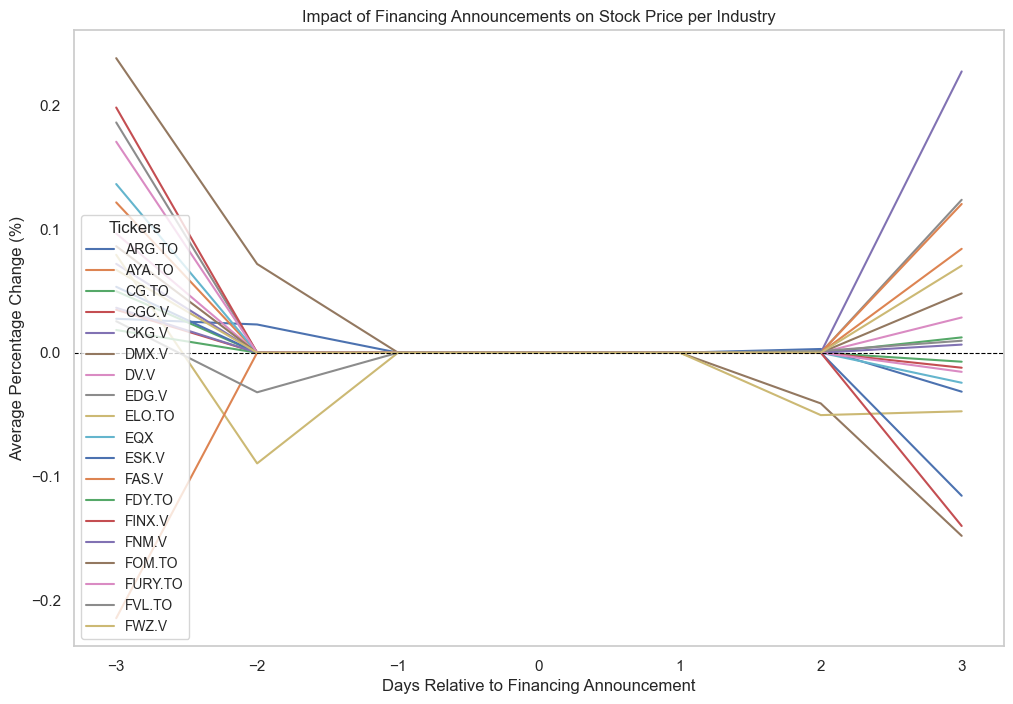

In [12]:
# Convert the Spark DataFrame to a Pandas DataFrame for visualization
average_changes_pd = average_changes_df.toPandas()

# Transpose the data to make the 'day' columns the index
average_changes_pd.set_index("ticker", inplace=True)
average_changes_transposed = average_changes_pd.transpose()

# Create a plot for visualization
plt.figure(figsize=(12, 8))

# Plot the average percentage changes for each day relative to financing announcements
for ticker in average_changes_transposed.columns:
    plt.plot(range(-3, 4), average_changes_transposed[ticker], label=ticker)

# Add labels, legend, and title
plt.xlabel("Days Relative to Financing Announcement")
plt.ylabel("Average Percentage Change (%)")
plt.title("Impact of Financing Announcements on Stock Price per Industry")
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.legend(title="Tickers", loc="best", fontsize='small')
plt.grid()

# Display the plot
plt.show()

## Now based on daily_returns

In [14]:
from pyspark.sql.window import Window
from pyspark.sql.functions import col, avg, lag

# Define a window specification partitioned by ticker and ordered by date
window_spec = Window.partitionBy("ticker").orderBy("Local Date (ET)")

# Calculate the percentage change for the specified days relative to financing announcements using 'daily_return'
for offset in range(-3, 4):  # -3 to +3 days
    joined_df = joined_df.withColumn(
        f"daily_return_change_day_{offset}",
        when(
            lag("daily_return", -offset).over(window_spec) != 0,
            ((col("daily_return") - lag("daily_return", -offset).over(window_spec)) / lag("daily_return", -offset).over(window_spec)) * 100
        ).otherwise(None)
    )

# Filter rows where a financing announcement occurred
financing_days_df = joined_df.filter(col("current_financing_announcement") == 1)

# Calculate the average percentage change for each ticker
average_changes_df = financing_days_df.groupBy("ticker").agg(
    *[avg(f"daily_return_change_day_{offset}").alias(f"avg_daily_return_change_day_{offset}") for offset in range(-3, 4)]
)

# Display the results
print("\nAverage percentage changes using daily return for each ticker:")
average_changes_df.show()


Average percentage changes using daily return for each ticker:
+-------+------------------------------+------------------------------+------------------------------+-----------------------------+-----------------------------+-----------------------------+-----------------------------+
| ticker|avg_daily_return_change_day_-3|avg_daily_return_change_day_-2|avg_daily_return_change_day_-1|avg_daily_return_change_day_0|avg_daily_return_change_day_1|avg_daily_return_change_day_2|avg_daily_return_change_day_3|
+-------+------------------------------+------------------------------+------------------------------+-----------------------------+-----------------------------+-----------------------------+-----------------------------+
| ARG.TO|           -15.426322384426744|            -9.226305430412308|                           0.0|                          0.0|                          0.0|           -4.445997929197425|          -24.688737275934717|
| AYA.TO|            -14.55214731258525|    

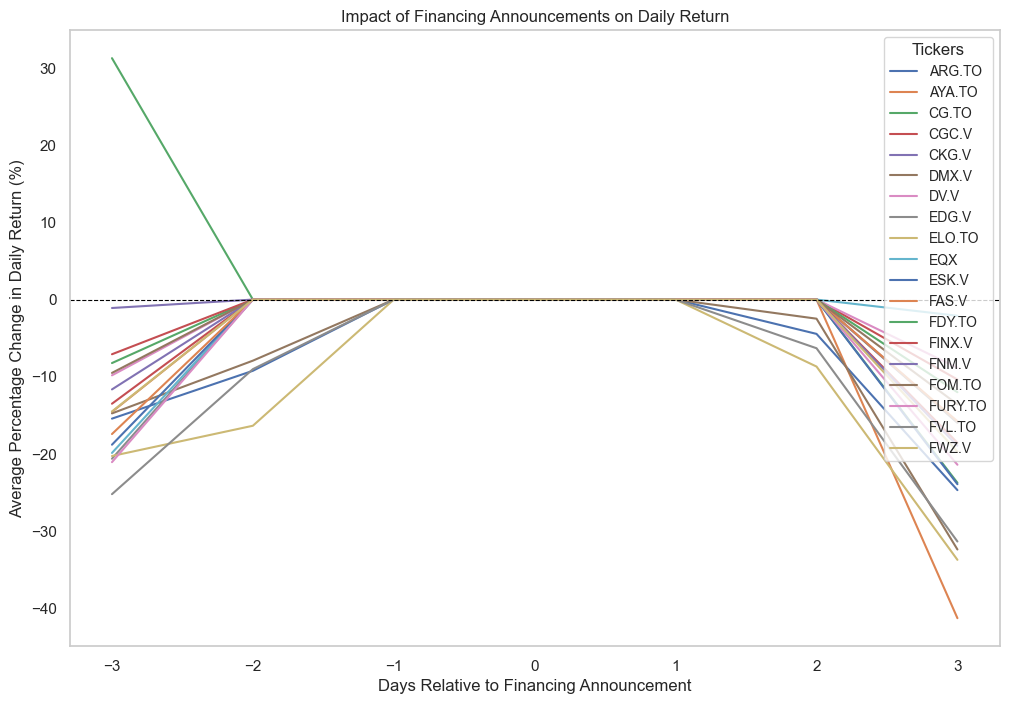

In [15]:
# Convert the Spark DataFrame to a Pandas DataFrame for visualization
average_changes_pd = average_changes_df.toPandas()

# Transpose the data to make the 'day' columns the index
average_changes_pd.set_index("ticker", inplace=True)
average_changes_transposed = average_changes_pd.transpose()

# Create a plot for visualization
plt.figure(figsize=(12, 8))

# Plot the average percentage changes for each day relative to financing announcements using 'daily_return'
for ticker in average_changes_transposed.columns:
    plt.plot(range(-3, 4), average_changes_transposed[ticker], label=ticker)

# Add labels, legend, and title
plt.xlabel("Days Relative to Financing Announcement")
plt.ylabel("Average Percentage Change in Daily Return (%)")
plt.title("Impact of Financing Announcements on Daily Return")
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.legend(title="Tickers", loc="best", fontsize='small')
plt.grid()

# Display the plot
plt.show()

In [16]:
from pyspark.sql.functions import col

# Filter the DataFrame to include only rows where a financing announcement occurred
financing_days_df = joined_df.filter(col("current_financing_announcement") == 1)


Average percentage changes using daily return for each ticker:
+-------+------------------------------+------------------------------+------------------------------+-----------------------------+-----------------------------+-----------------------------+-----------------------------+
| ticker|avg_daily_return_change_day_-3|avg_daily_return_change_day_-2|avg_daily_return_change_day_-1|avg_daily_return_change_day_0|avg_daily_return_change_day_1|avg_daily_return_change_day_2|avg_daily_return_change_day_3|
+-------+------------------------------+------------------------------+------------------------------+-----------------------------+-----------------------------+-----------------------------+-----------------------------+
| ARG.TO|           -15.426322384426744|            -9.226305430412308|                           0.0|                          0.0|                          0.0|           -4.445997929197425|          -24.688737275934717|
| AYA.TO|            -14.55214731258525|    

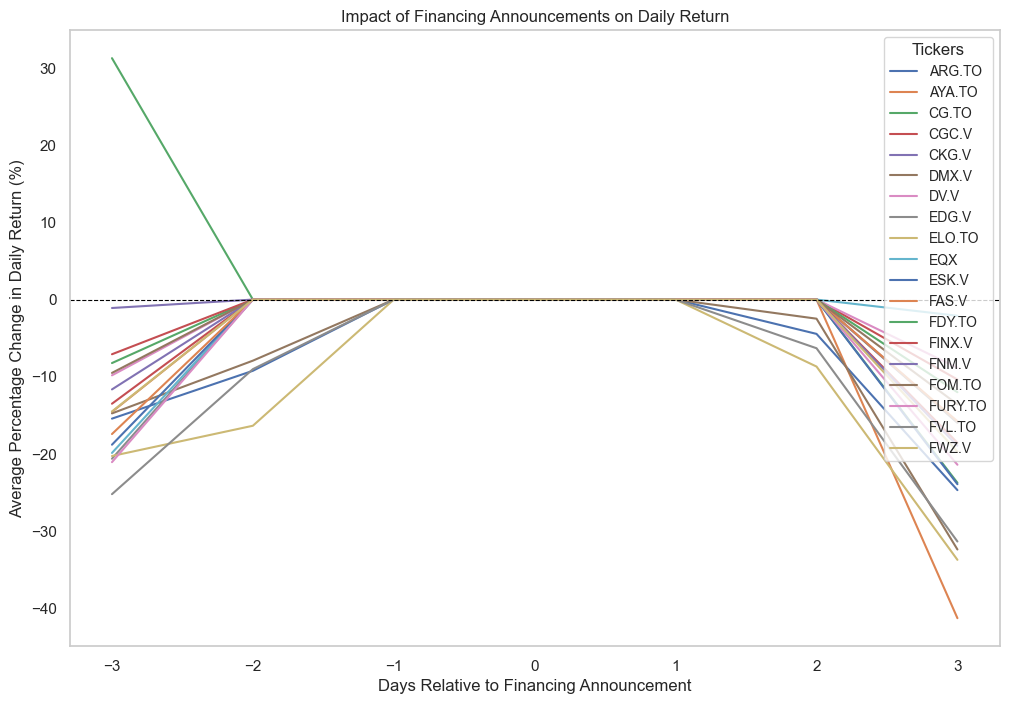

In [18]:
from pyspark.sql.functions import col, avg, lag

# Define a window specification partitioned by ticker and ordered by date
window_spec = Window.partitionBy("ticker").orderBy("Local Date (ET)")

# Calculate the percentage change for the specified days relative to financing announcements using 'daily_return'
for offset in range(-3, 4):  # -3 to +3 days
    joined_df = joined_df.withColumn(
        f"daily_return_change_day_{offset}",
        when(
            lag("daily_return", -offset).over(window_spec) != 0,
            ((col("daily_return") - lag("daily_return", -offset).over(window_spec)) / lag("daily_return", -offset).over(window_spec)) * 100
        ).otherwise(None)
    )

# Filter rows where a financing announcement occurred
financing_days_df = joined_df.filter(col("current_financing_announcement") == 1)

# Calculate the average percentage change for each ticker
average_changes_df = financing_days_df.groupBy("ticker").agg(
    *[avg(f"daily_return_change_day_{offset}").alias(f"avg_daily_return_change_day_{offset}") for offset in range(-3, 4)]
)

# Display the results
print("\nAverage percentage changes using daily return for each ticker:")
average_changes_df.show()

# Convert the Spark DataFrame to a Pandas DataFrame for visualization
average_changes_pd = average_changes_df.toPandas()

# Transpose the data to make the 'day' columns the index
average_changes_pd.set_index("ticker", inplace=True)
average_changes_transposed = average_changes_pd.transpose()

# Create a plot for visualization
plt.figure(figsize=(12, 8))

# Plot the average percentage changes for each day relative to financing announcements using 'daily_return'
for ticker in average_changes_transposed.columns:
    plt.plot(range(-3, 4), average_changes_transposed[ticker], label=ticker)

# Add labels, legend, and title
plt.xlabel("Days Relative to Financing Announcement")
plt.ylabel("Average Percentage Change in Daily Return (%)")
plt.title("Impact of Financing Announcements on Daily Return")
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.legend(title="Tickers", loc="best", fontsize='small')
plt.grid()

# Display the plot
plt.show()

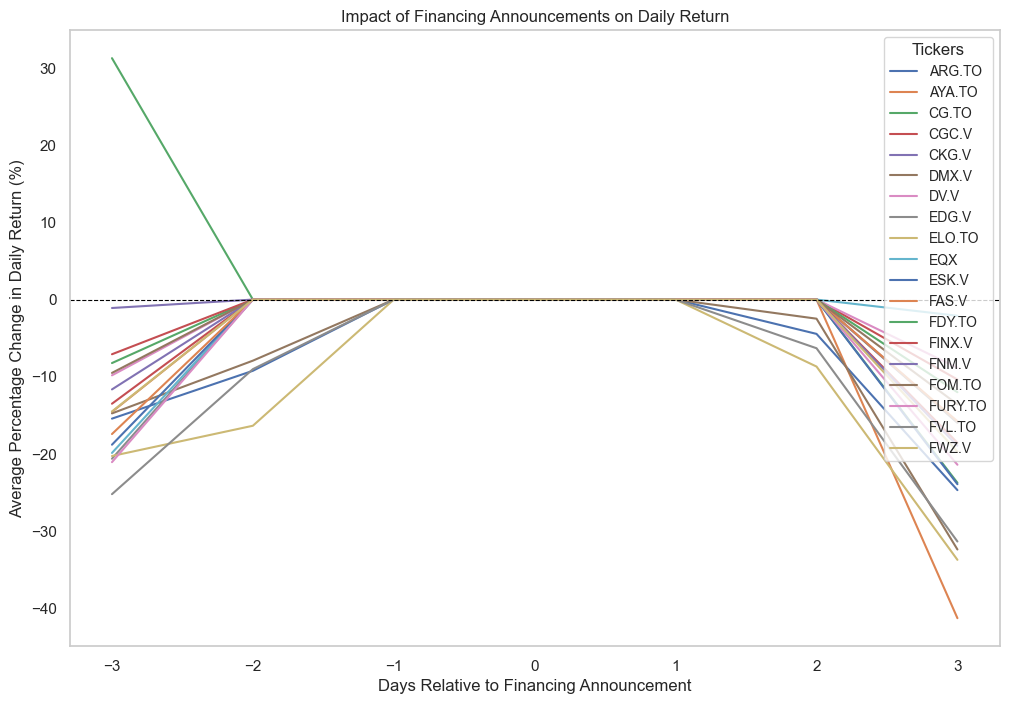

In [20]:
from pyspark.sql.functions import col, avg, lag
from pyspark.sql.window import Window
import matplotlib.pyplot as plt

# Define a window specification partitioned by ticker and ordered by date
window_spec = Window.partitionBy("ticker").orderBy("Local Date (ET)")

# Calculate the percentage change for the specified days relative to financing announcements using 'daily_return'
for offset in range(-3, 4):  # -3 to +3 days
    joined_df = joined_df.withColumn(
        f"daily_return_change_day_{offset}",
        when(
            lag("daily_return", -offset).over(window_spec) != 0,
            ((col("daily_return") - lag("daily_return", -offset).over(window_spec)) / lag("daily_return", -offset).over(window_spec)) * 100
        ).otherwise(None)
    )

# Filter rows where a financing announcement occurred
financing_days_df = joined_df.filter(col("current_financing_announcement") == 1)

# Calculate the average percentage change for each ticker
average_changes_df = financing_days_df.groupBy("ticker").agg(
    *[avg(f"daily_return_change_day_{offset}").alias(f"avg_daily_return_change_day_{offset}") for offset in range(-3, 4)]
)

# Convert the Spark DataFrame to a Pandas DataFrame for visualization
average_changes_pd = average_changes_df.toPandas()

# Transpose the data to make the 'day' columns the index
average_changes_pd.set_index("ticker", inplace=True)
average_changes_transposed = average_changes_pd.transpose()

# Create a plot for visualization
plt.figure(figsize=(12, 8))

# Plot the average percentage changes for each day relative to financing announcements using 'daily_return'
for ticker in average_changes_transposed.columns:
    plt.plot(range(-3, 4), average_changes_transposed[ticker], label=ticker)

# Add labels, legend, and title
plt.xlabel("Days Relative to Financing Announcement")
plt.ylabel("Average Percentage Change in Daily Return (%)")
plt.title("Impact of Financing Announcements on Daily Return")
plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.legend(title="Tickers", loc="best", fontsize='small')
plt.grid()

# Display the plot
plt.show()

In [ ]:
from pyspark.sql.window import Window
from pyspark.sql.functions import col, avg, when

# Define a window specification partitioned by ticker and ordered by date
window_spec = Window.partitionBy("ticker").orderBy("Local Date (ET)")

# Calculate the percentage change for the specified days relative to financing announcements
for offset in range(-3, 4):  # -3 to +3 days
    joined_df = joined_df.withColumn(
        f"price_change_day_{offset}",
        ((col("Close") - lag("Close", -offset).over(window_spec)) / lag("Close", -offset).over(window_spec)) * 100
    )

# Filter rows where a financing announcement occurred
financing_days_df = joined_df.filter(col("current_financing_announcement") == 1)

# Calculate the average percentage change for each ticker
average_changes_df = financing_days_df.groupBy("ticker").agg(
    *[avg(f"price_change_day_{offset}").alias(f"avg_price_change_day_{offset}") for offset in range(-3, 4)]
)

# Display the results
print("\nAverage percentage changes for each ticker:")
average_changes_df.show()

In [48]:
from pyspark.sql.window import Window
from pyspark.sql.functions import lag, lead, col, avg

# Define a window specification to calculate stock prices before and after announcements
window_spec = Window.partitionBy("ticker").orderBy("Local Date (ET)")

# Calculate the daily return one day before and one day after the announcement
joined_df = joined_df.withColumn("return_before", lag("daily_return", 1).over(window_spec))
joined_df = joined_df.withColumn("return_after", lead("daily_return", 1).over(window_spec))

# Calculate the percentage change in daily return, handling division by zero
joined_df = joined_df.withColumn(
    "return_change",
    when(col("return_before") != 0, ((col("return_after") - col("return_before")) / col("return_before")) * 100)
    .otherwise(None)
)

# Filter rows where return_before or return_after is null (e.g., first or last row in the window)
joined_df = joined_df.filter(col("return_before").isNotNull() & col("return_after").isNotNull())

# Group by ticker and calculate the average return change
impact_analysis_df = joined_df.groupBy("ticker").agg(
    avg("return_change").alias("avg_return_change")
)

# Display the results
print("\nImpact analysis results:")
impact_analysis_df.show(10)


Impact analysis results:
+------+-------------------+
|ticker|  avg_return_change|
+------+-------------------+
|ARG.TO|-17.756311636198014|
|AYA.TO|-11.963730144623351|
| CG.TO| 0.3373419597201713|
| CGC.V| -14.11294349437865|
| CKG.V| -9.994288835433116|
| DMX.V|-13.441410345237543|
|  DV.V|  -9.18419019535586|
| EDG.V|-15.245217706764402|
|ELO.TO|-19.108984690148596|
|   EQX|-17.949048757493426|
+------+-------------------+
only showing top 10 rows


In [39]:
# Strict filter: Keep rows only where daily_return is non-null for analysis periods
joined_df = joined_df.filter(col("daily_return").isNotNull())

In [49]:
joined_df.show(5)

+------+--------+---------------+-----+--------------------+-------------+--------------------+--------------------+-----------------+
|ticker|industry|Local Date (ET)|Close|        daily_return|has_financing|       return_before|        return_after|    return_change|
+------+--------+---------------+-----+--------------------+-------------+--------------------+--------------------+-----------------+
|ARG.TO|  Copper|     2024-01-16| 1.35|-0.02173913043478...|            0|-0.02173913043478...|-0.02173913043478...|             -0.0|
|ARG.TO|  Copper|     2024-01-16| 1.35|-0.02173913043478...|            0|-0.02173913043478...|-0.02173913043478...|             -0.0|
|ARG.TO|  Copper|     2024-01-16| 1.35|-0.02173913043478...|            0|-0.02173913043478...|-0.02962962962962...|36.29629629629728|
|ARG.TO|  Copper|     2024-01-17| 1.31|-0.02962962962962...|            0|-0.02173913043478...|-0.02962962962962...|36.29629629629728|
|ARG.TO|  Copper|     2024-01-17| 1.31|-0.0296296296296

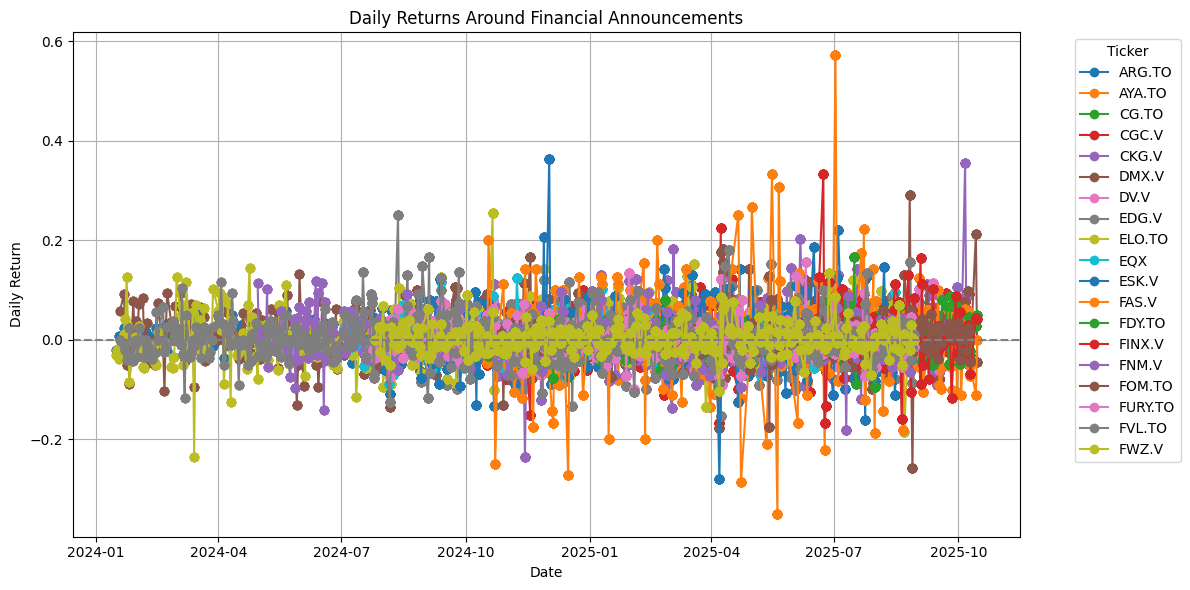

In [55]:
import matplotlib.pyplot as plt

# Convert the DataFrame to Pandas for easy plotting
plot_data = filtered_df.select("ticker", "Local Date (ET)", "daily_return").toPandas()

# Plot daily returns for each ticker
plt.figure(figsize=(12, 6))
for ticker in plot_data["ticker"].unique():
    ticker_data = plot_data[plot_data["ticker"] == ticker]
    plt.plot(
        ticker_data["Local Date (ET)"], 
        ticker_data["daily_return"],
        label=ticker,
        marker="o"
    )

# Format the plot
plt.axhline(y=0, color="gray", linestyle="--")  # Add baseline for daily return
plt.title("Daily Returns Around Financial Announcements")
plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.legend(title="Ticker", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

In [60]:
filtered_df.select("Local Date (ET)").show(20, truncate=False)

+---------------+
|Local Date (ET)|
+---------------+
|2024-01-16     |
|2024-01-16     |
|2024-01-16     |
|2024-01-17     |
|2024-01-17     |
|2024-01-17     |
|2024-01-17     |
|2024-01-18     |
|2024-01-18     |
|2024-01-18     |
|2024-01-18     |
|2024-01-19     |
|2024-01-19     |
|2024-01-19     |
|2024-01-19     |
|2024-01-22     |
|2024-01-22     |
|2024-01-22     |
|2024-01-22     |
|2024-01-23     |
+---------------+
only showing top 20 rows


In [70]:
from pyspark.sql.window import Window
from pyspark.sql.functions import col, datediff, when, last

# Define a window to find the last financing date (where has_financing = 1) for each ticker
window_spec = Window.partitionBy("ticker").orderBy(col("Local Date (ET)").asc()).rowsBetween(Window.unboundedPreceding, 0)

# Add financing_date for rows where `has_financing == 1`
joined_df = joined_df.withColumn(
    "financing_date",
    last(when(col("has_financing") == 1, col("Local Date (ET)"))).over(window_spec)
)

# Calculate relative_day based on the financing_date
joined_df = joined_df.withColumn(
    "relative_day",
    datediff(col("Local Date (ET)"), col("financing_date"))
)

# Inspect the resulting DataFrame
joined_df.select("ticker", "Local Date (ET)", "financing_date", "relative_day", "daily_return").show(20, truncate=False)

+------+---------------+--------------+------------+---------------------+
|ticker|Local Date (ET)|financing_date|relative_day|daily_return         |
+------+---------------+--------------+------------+---------------------+
|ARG.TO|2024-01-15     |NULL          |NULL        |NULL                 |
|ARG.TO|2024-01-15     |NULL          |NULL        |NULL                 |
|ARG.TO|2024-01-15     |NULL          |NULL        |NULL                 |
|ARG.TO|2024-01-15     |NULL          |NULL        |NULL                 |
|ARG.TO|2024-01-16     |NULL          |NULL        |-0.021739130434782483|
|ARG.TO|2024-01-16     |NULL          |NULL        |-0.021739130434782483|
|ARG.TO|2024-01-16     |NULL          |NULL        |-0.021739130434782483|
|ARG.TO|2024-01-16     |NULL          |NULL        |-0.021739130434782483|
|ARG.TO|2024-01-17     |NULL          |NULL        |-0.029629629629629672|
|ARG.TO|2024-01-17     |NULL          |NULL        |-0.029629629629629672|
|ARG.TO|2024-01-17     |N

In [68]:
from pyspark.sql.window import Window
from pyspark.sql.functions import col, datediff, first

# Create a window to find the closest financing announcement for each ticker
window_spec = Window.partitionBy("ticker").orderBy(col("Local Date (ET)").asc())

# Add a column with the financing date (where has_financing = 1)
joined_df = joined_df.withColumn(
    "financing_date",
    first(when(col("has_financing") == 1, col("Local Date (ET)"))).over(window_spec)
)

# Calculate relative_day based on the financing_date
joined_df = joined_df.withColumn(
    "relative_day",
    datediff(col("Local Date (ET)"), col("financing_date"))
)

# Inspect the resulting DataFrame
joined_df.select("ticker", "Local Date (ET)", "financing_date", "relative_day").show(20, truncate=False)

+------+---------------+--------------+------------+
|ticker|Local Date (ET)|financing_date|relative_day|
+------+---------------+--------------+------------+
|ARG.TO|2024-01-15     |NULL          |NULL        |
|ARG.TO|2024-01-15     |NULL          |NULL        |
|ARG.TO|2024-01-15     |NULL          |NULL        |
|ARG.TO|2024-01-15     |NULL          |NULL        |
|ARG.TO|2024-01-16     |NULL          |NULL        |
|ARG.TO|2024-01-16     |NULL          |NULL        |
|ARG.TO|2024-01-16     |NULL          |NULL        |
|ARG.TO|2024-01-16     |NULL          |NULL        |
|ARG.TO|2024-01-17     |NULL          |NULL        |
|ARG.TO|2024-01-17     |NULL          |NULL        |
|ARG.TO|2024-01-17     |NULL          |NULL        |
|ARG.TO|2024-01-17     |NULL          |NULL        |
|ARG.TO|2024-01-18     |NULL          |NULL        |
|ARG.TO|2024-01-18     |NULL          |NULL        |
|ARG.TO|2024-01-18     |NULL          |NULL        |
|ARG.TO|2024-01-18     |NULL          |NULL   

## laatste keer proberen

In [75]:
from pyspark.sql.functions import col

# Join daily_data_df and biweekly_data_df on ticker and biweekly_index
joined_df = daily_data_df.join(
    biweekly_data_df,
    on=["ticker", "biweekly_index"],
    how="inner"
)

# Inspect the joined DataFrame
joined_df.show(5)

+------+--------------+---------------+----+----+----+-----+--------+--------------------+-------------------+--------------------+--------------------+--------------------+------+--------+---------+-----------+----------------+---------------+--------------------+--------+--------+---------------+--------------------+---------+------------+----------+-----------+------------+-----------+----------+------------------+--------------------+-----------------------+--------------------+--------------------+-------------------+--------------------+--------------------+------------+----------------+----------------+-----------------+------------------+--------------------+---------+--------------------+-------+-------+---------+---------------------+------------------------+-----------------------+--------+------------------+-------------------------+-------------+------------------+---------------------+---------------------+----------------------+--------------+------------------------+---

In [76]:
financing_df = joined_df.filter(col("has_financing") == 1)
financing_df.show(5)

+------+--------------+---------------+-----+-----+-----+-----+--------+--------------------+------------------+--------------------+--------------------+--------------------+------+--------+---------+-----------+----------------+---------------+--------------------+--------------------+--------------------+---------------+--------------------+---------+------------+----------+-----------+------------+-----------+----------+---------+-------------+-----------------------+------------------+--------------------+-------------------+-------------------+-------------------+------------+----------------+----------------+-----------------+------------------+--------------------+---------+-------------------+-------------------+-------+---------+---------------------+------------------------+-----------------------+--------+------------------+-------------------------+-------------+-------------------+---------------------+---------------------+----------------------+--------------+----------

In [78]:
from pyspark.sql.window import Window
from pyspark.sql.functions import datediff

# Define a window for grouping by ticker and ordering by date
window_spec = Window.partitionBy("ticker").orderBy(col("Local Date (ET)").asc()).rowsBetween(Window.unboundedPreceding, 0)

# Add financing_date column using the last financing date for each ticker
from pyspark.sql.functions import last, when

joined_df = joined_df.withColumn(
    "financing_date",
    last(when(col("has_financing") == 1, col("Local Date (ET)")), ignorenulls=True).over(window_spec)
)

# Calculate relative_day as the difference between Local Date (ET) and financing_date
joined_df = joined_df.withColumn(
    "relative_day",
    datediff(col("Local Date (ET)"), col("financing_date"))
)

# Inspect the resulting DataFrame
joined_df.select("ticker", "Local Date (ET)", "relative_day", "daily_return", "has_financing").show(20, truncate=False)

+------+---------------+------------+---------------------+-------------+
|ticker|Local Date (ET)|relative_day|daily_return         |has_financing|
+------+---------------+------------+---------------------+-------------+
|ARG.TO|2024-01-15     |NULL        |NULL                 |0            |
|ARG.TO|2024-01-16     |NULL        |-0.021739130434782483|0            |
|ARG.TO|2024-01-17     |NULL        |-0.029629629629629672|0            |
|ARG.TO|2024-01-18     |NULL        |0.007633587786259444 |0            |
|ARG.TO|2024-01-19     |NULL        |-0.030303030303030276|0            |
|ARG.TO|2024-01-22     |NULL        |0.0234375            |0            |
|ARG.TO|2024-01-23     |NULL        |0.007633587786259444 |0            |
|ARG.TO|2024-01-24     |NULL        |-0.015151515151515138|0            |
|ARG.TO|2024-01-25     |NULL        |0.023076923076922995 |0            |
|ARG.TO|2024-01-26     |NULL        |0.007518796992481258 |0            |
|ARG.TO|2024-01-29     |NULL        |-

In [79]:
windowed_df = joined_df.filter((col("relative_day") >= -3) & (col("relative_day") <= 3))
windowed_df.show(20, truncate=False)

+------+--------------+---------------+-----+-----+-----+-----+--------+---------------------+-------------------+---------------------+--------------------+---------------------+------+--------+---------+-----------+----------------+---------------+-------------------------+------------------------------+------------------------------+---------------+-------------------------+---------+------------+----------+-----------+------------+-----------+----------+-------------------+--------------------+-----------------------+-------------------+--------------------+--------------------+-------------------+-------------------+------------+------------------+----------------+------------------+------------------+--------------------+---------+--------------------+-------------------+-------+---------+---------------------+------------------------+-----------------------+--------+-------------------+-------------------------+-------------+--------------------+---------------------+-----------

In [80]:
from pyspark.sql.functions import avg

average_returns_df = windowed_df.groupBy("ticker", "relative_day").agg(
    avg("daily_return").alias("avg_daily_return")
)

# Inspect the aggregated averages
average_returns_df.orderBy("ticker", "relative_day").show(20, truncate=False)

+-------+------------+----------------------+
|ticker |relative_day|avg_daily_return      |
+-------+------------+----------------------+
|AYA.TO |0           |-0.005743708490237287 |
|AYA.TO |3           |0.010120839516642     |
|CGC.V  |0           |0.004582604375453724  |
|CGC.V  |3           |0.03464912280701754   |
|DMX.V  |0           |0.01735749866457965   |
|DV.V   |0           |0.01704112569006309   |
|DV.V   |3           |-0.024590163934426257 |
|ELO.TO |0           |-0.013637350776628991 |
|ELO.TO |3           |-0.00870855289405419  |
|FAS.V  |0           |-0.0014555763429971909|
|FAS.V  |3           |0.003703703703703709  |
|FDY.TO |0           |-5.538127562665771E-4 |
|FDY.TO |3           |-0.0019810697776799224|
|FNM.V  |0           |0.002857822760959691  |
|FNM.V  |3           |0.01731786731786737   |
|FOM.TO |0           |-0.023532171155542136 |
|FOM.TO |3           |-0.08750000000000002  |
|FURY.TO|0           |0.01868937797985949   |
|FURY.TO|3           |0.0449486301

In [81]:
plot_data = average_returns_df.toPandas()

# Pivot data for plotting: relative_day as columns, tickers as rows
pivot_data = plot_data.pivot(index="ticker", columns="relative_day", values="avg_daily_return")

# Inspect the pivoted data
print(pivot_data)

relative_day         0         3
ticker                          
AYA.TO       -0.005744  0.010121
CGC.V         0.004583  0.034649
DMX.V         0.017357       NaN
DV.V          0.017041 -0.024590
ELO.TO       -0.013637 -0.008709
FAS.V        -0.001456  0.003704
FDY.TO       -0.000554 -0.001981
FNM.V         0.002858  0.017318
FOM.TO       -0.023532 -0.087500
FURY.TO       0.018689  0.044949
FVL.TO        0.012701  0.002558
FWZ.V         0.002971  0.043750


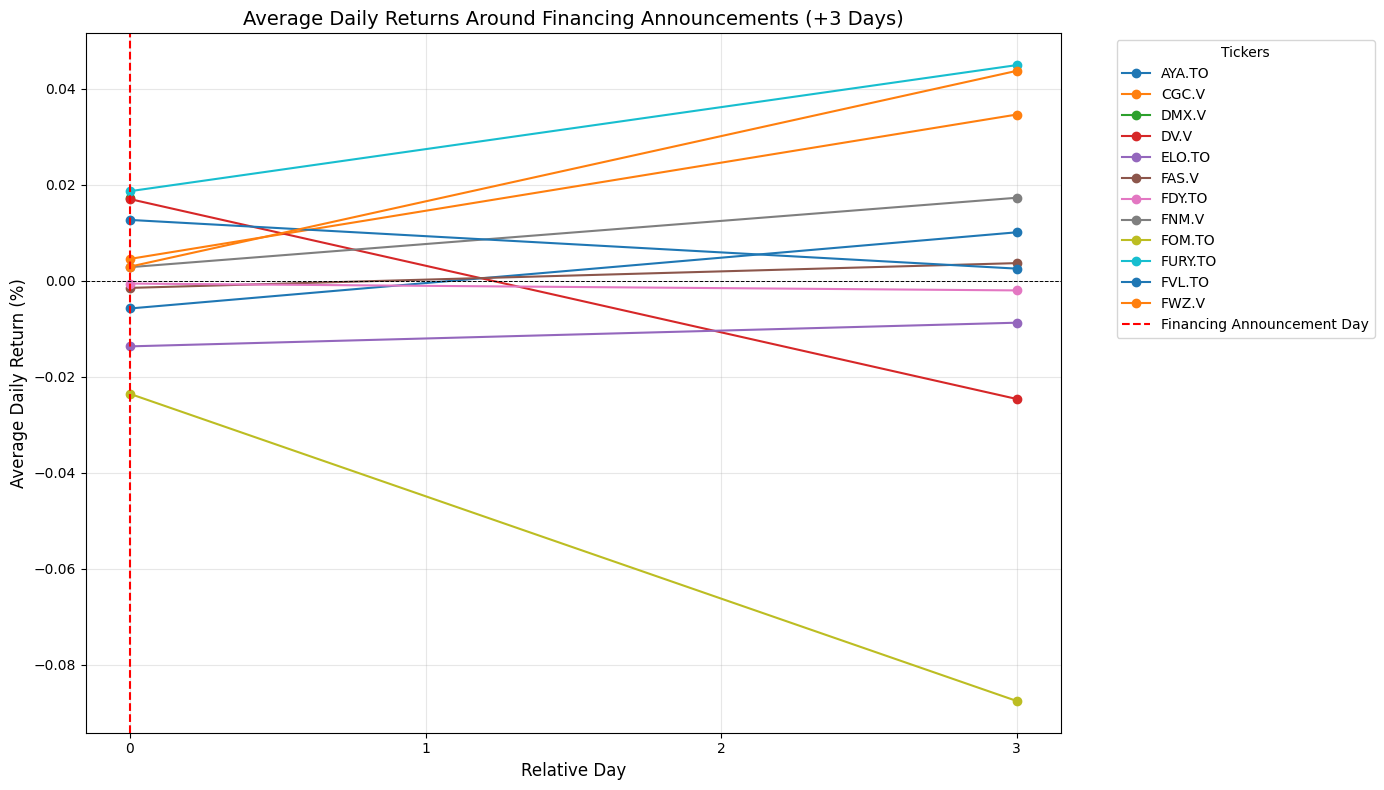

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
for ticker in pivot_data.index:
    plt.plot(
        pivot_data.columns,                     # Relative day range (-3 to +3)
        pivot_data.loc[ticker],                 # Daily returns for the ticker
        marker="o",                             # Highlight data points with markers
        label=ticker                            # Ticker label for the legend
    )

# Add visual elements for better interpretation
plt.axhline(0, color="black", linestyle="--", linewidth=0.7)  # Baseline for daily return
plt.axvline(0, color="red", linestyle="--", label="Financing Announcement Day")  # Financing announcement day (Day 0)

# Format the plot
plt.title("Average Daily Returns Around Financing Announcements (+3 Days)", fontsize=14)
plt.xlabel("Relative Day", fontsize=12)
plt.ylabel("Average Daily Return (%)", fontsize=12)
plt.xticks(range(0, 4))  # Set ticks from 0 to +3
plt.legend(title="Tickers", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=10)
plt.grid(alpha=0.3)  # Add grid for better readability
plt.tight_layout()
plt.show()

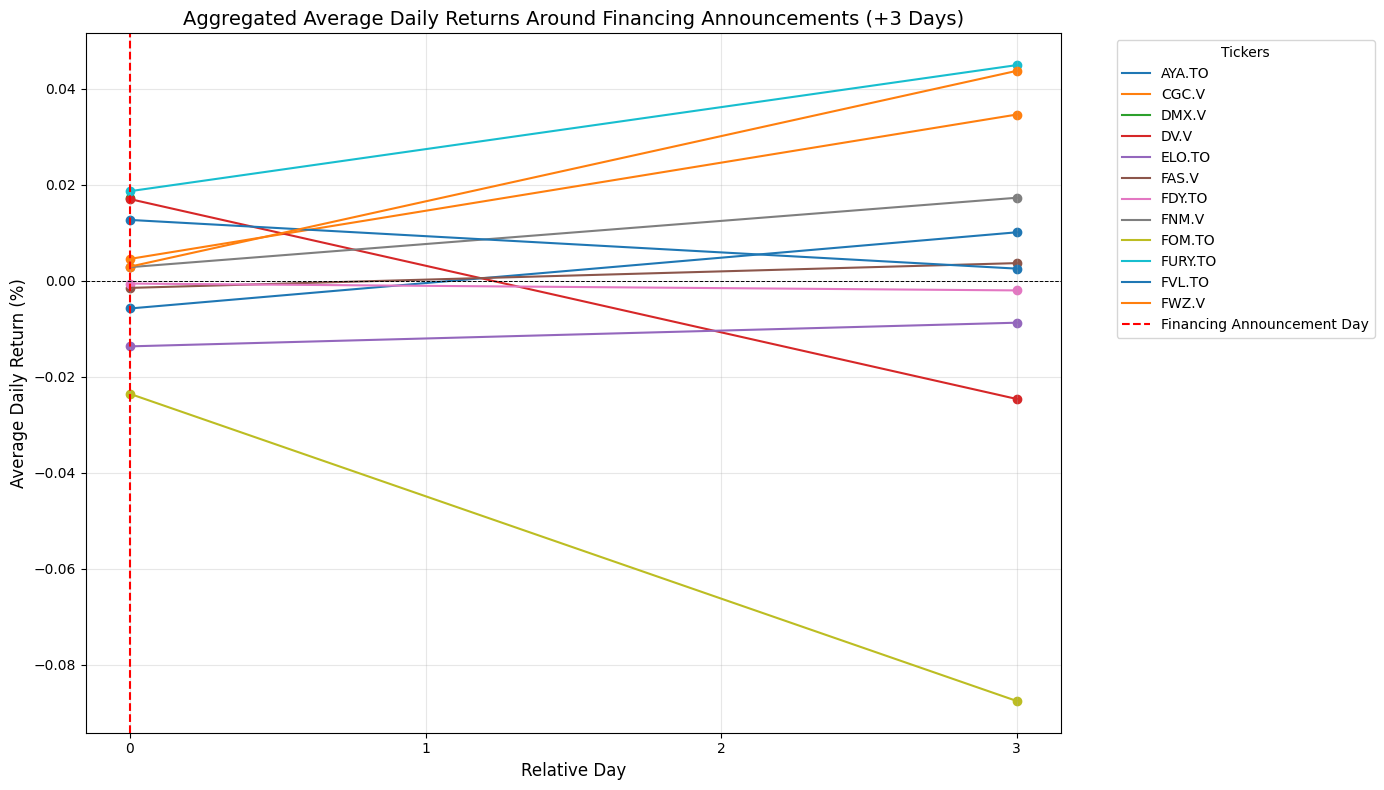

In [88]:
import matplotlib.pyplot as plt

# Aggregate daily returns (average per ticker per day)
aggregated_plot_data = windowed_df.groupBy("ticker", "relative_day").agg(
    avg("daily_return").alias("avg_daily_return")
).toPandas()

# Pivot data for plotting: Tickers as rows, relative day as columns
pivot_data = aggregated_plot_data.pivot(index="ticker", columns="relative_day", values="avg_daily_return")

# Create the plot
plt.figure(figsize=(14, 8))
for ticker in pivot_data.index:
    plt.plot(
        pivot_data.columns,                     # Relative day range (0 to +3 days after announcement)
        pivot_data.loc[ticker],                 # Daily returns for the ticker
        label=ticker                            # Ticker label for the legend
    )
    plt.scatter(
        pivot_data.columns,
        pivot_data.loc[ticker],
        marker="o"                              # Add dots for each day after announcement
    )

# Add vertical and horizontal reference lines
plt.axvline(0, color="red", linestyle="--", label="Financing Announcement Day")  # Financing day marker
plt.axhline(0, color="black", linestyle="--", linewidth=0.7)  # Baseline marker

# Customize plot
plt.title("Aggregated Average Daily Returns Around Financing Announcements (+3 Days)", fontsize=14)
plt.xlabel("Relative Day", fontsize=12)
plt.ylabel("Average Daily Return (%)", fontsize=12)
plt.xticks(range(0, 4))  # Days 0 to +3
plt.legend(title="Tickers", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=10)
plt.grid(alpha=0.3)  # Add grid for clarity
plt.tight_layout()
plt.show()